# Does rotation-based test-time training (TTT) help on corrupted CIFAR-10?

Two models share one architecture (see diagram: shared stages 1-2, then a classification branch and a 4-way rotation branch, each with its own stage-3 copy). They are compared on **CIFAR-10-C Gaussian noise, severity 5** and on **clean CIFAR-10**:

| Run | How it was trained | How it is tested |
|---|---|---|
| Main task only, frozen | classification loss only (CE_cls) | no updates |
| Joint, frozen | classification + rotation loss (CE_cls + CE_rot) | no updates |
| Joint + TTT episodic | CE_cls + CE_rot | shared extractor updated on each test image with the rotation loss, then **reset** to the checkpoint before the next image |
| Joint + TTT online | CE_cls + CE_rot | shared extractor updated along the test stream, updates **carry forward** |

At test time only the shared extractor θe (stages 1 and 2) is updated. Both stage-3 branches and both linear heads stay frozen. Normalization layers are **GroupNorm** (8 groups).

**Held-out monitor.** ttt_dev is never adapted on. While online TTT runs through the 8,000-image evaluation stream, the current weights are scored on ttt_dev (frozen, no TTT on those images) before the first update and after every 100 stream images. That gives a curve: x = stream images TTT has adapted on, y = accuracy on held-out ttt_dev. Both the noisy and the clean versions of the ttt_dev pictures are scored, so the curve also shows whether adapting to noise hurts clean images.

**TTT settings** (Sun et al. 2020 defaults): lr 1e-3, 10 steps per image for episodic, 1 step per image for online.

## How to run on Kaggle
1. Settings → Accelerator: **GPU** (T4 x1 or P100). Settings → **Internet on**: CIFAR-10 comes from torchvision, and CIFAR-10-C is streamed from Zenodo record 2535967. Only the needed `.npy` files are kept.
2. Recommended first: set `CFG['quick'] = True` in the config cell and Run All as a smoke test (2 epochs, 300 evaluation images). Then set it back to `False`.
3. Run All. If checkpoints with the same settings already exist in `ttt_runs/checkpoints/`, training is skipped.
4. Only after the small run works: uncomment the expansion line in section 11 and run that cell.

Headless alternative: `jupyter nbconvert --to notebook --execute --ExecutePreprocessor.timeout=-1 ttt_cifar10c_rotation.ipynb --output ttt_executed.ipynb`

## Data split (seed 0)
| Split | Taken from | Size | Used for |
|---|---|---|---|
| source_train | CIFAR-10 train | 45,000 | training both models |
| source_dev | CIFAR-10 train, held out | 5,000 | best-epoch selection, source-training results |
| ttt_dev | CIFAR-10 test indices, clean and noisy versions | 2,000 | **held-out monitor only**: scored after every 100 stream images, never adapted on |
| evaluation | CIFAR-10 test indices, clean and noisy versions | 8,000 | the TTT stream and the final comparison |

CIFAR-10-C is generated from the CIFAR-10 test images in the same order, so one set of test indices defines ttt_dev and evaluation for both clean and noisy images. The two sets share no pictures. The exact indices are saved to `splits.npz`.

## Outputs in `/kaggle/working/ttt_runs/`
- `checkpoints/supervised_best.pt` (main task only), `checkpoints/joint_best.pt` (and `*_last.pt`)
- `config.json`: every setting, seeds, library versions, GPU, run command
- `splits.npz`, `results/split.csv`, `logs/*_history.csv`
- `results/source_results.csv`, `results/results.csv`, `results/predictions.npz`
- `results/heldout_curve.csv`: held-out ttt_dev accuracy after every 100 stream images
- `results/figures/*.png`: every figure, each line or bar labelled with how the model was trained and how it was evaluated
- `results/summary.md` and `results/notes.md`

## 1. Config, seeds, paths

In [1]:
import os, sys, json, time, math, copy, random, tarfile, platform, datetime
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import requests
from scipy.stats import binomtest
from IPython.display import display, Markdown

NL = chr(10)
ON_KAGGLE = os.path.isdir('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('.')

ALL_CORRUPTIONS = ['gaussian_noise', 'shot_noise', 'impulse_noise', 'defocus_blur', 'glass_blur',
                   'motion_blur', 'zoom_blur', 'snow', 'frost', 'fog', 'brightness', 'contrast',
                   'elastic_transform', 'pixelate', 'jpeg_compression']

CFG = {
    'quick': False,                 # True = smoke test: 2 epochs, 300 eval images
    # ---- data / split ----
    'corruption': 'gaussian_noise',
    'severity': 5,
    'expand_corruptions': [],       # leave empty for the first run; see section 11
    'expand_episodic': False,       # episodic TTT is slow; expansion runs frozen + online by default
    'source_dev_size': 5000,
    'ttt_dev_size': 2000,
    'dev_limit': None,
    'eval_limit': None,
    'seed': 0,
    # ---- source training ----
    'epochs': 30,
    'batch_size': 128,
    'lr': 0.05,                     # SGD nesterov, one-cycle schedule
    'weight_decay': 5e-4,
    'rot_weight': 1.0,              # joint loss = CE_cls + rot_weight * CE_rot
    'gn_groups': 8,
    'amp': True,
    'reuse_checkpoints': True,      # skip training when a checkpoint with identical settings exists
    # ---- test-time training ----
    'ttt_batch': 32,                # augmented copies of ONE test image; rotation labels cycle 0,90,180,270
    'ttt_augment': True,            # random crop + flip on the copies
    'ttt_momentum': 0.0,
    # Sun et al. 2020 defaults
    'episodic_lr': 1e-3, 'episodic_steps': 10,
    'online_lr': 1e-3, 'online_steps': 1,
    'online_update_images': 1,      # 1 = one update per stream image (standard online TTT);
                                    # 100 = one update per chunk of 100 stream images (each image at 4 rotations)
    'monitor_every': 100,           # score the current weights on held-out ttt_dev every 100 stream images
    # ---- paths ----
    'data_dir': '/tmp/ttt_data',
    'out_dir': os.path.join(WORK, 'ttt_runs'),
}

if CFG['quick']:
    CFG.update({'epochs': 2, 'eval_limit': 300, 'dev_limit': 300,
                'out_dir': os.path.join(WORK, 'ttt_runs_quick')})

CKPT_DIR = os.path.join(CFG['out_dir'], 'checkpoints')
RES_DIR = os.path.join(CFG['out_dir'], 'results')
LOG_DIR = os.path.join(CFG['out_dir'], 'logs')
for d in (CFG['data_dir'], CKPT_DIR, RES_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP = bool(CFG['amp'] and DEV.type == 'cuda')
torch.backends.cudnn.benchmark = True

SEEDS = {'split': CFG['seed'], 'init_and_training': CFG['seed'],
         'ttt_augmentation': CFG['seed'] + 100, 'online_stream_order': CFG['seed'] + 1}

NOTES = []   # runtime problems are collected here and written to notes.md
if DEV.type != 'cuda':
    NOTES.append('No GPU found: ran on CPU. Full training and episodic TTT are very slow on CPU.')
if CFG['quick']:
    NOTES.append('QUICK smoke-test mode: 2 epochs and 300 evaluation images. Numbers only show that the pipeline runs.')

RUN_COMMAND = ('Kaggle: Accelerator GPU, Internet on, Run All. Headless: jupyter nbconvert --to notebook --execute '
               '--ExecutePreprocessor.timeout=-1 ttt_cifar10c_rotation.ipynb --output ttt_executed.ipynb')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def save_config(extra=None):
    info = {'cfg': CFG, 'seeds': SEEDS, 'run_command': RUN_COMMAND,
            'python': platform.python_version(), 'torch': torch.__version__,
            'torchvision': torchvision.__version__,
            'device': torch.cuda.get_device_name(0) if DEV.type == 'cuda' else 'cpu',
            'amp': USE_AMP, 'cudnn_benchmark': True,
            'saved_at': datetime.datetime.now().isoformat(timespec='seconds')}
    if extra:
        info.update(extra)
    with open(os.path.join(CFG['out_dir'], 'config.json'), 'w') as f:
        json.dump(info, f, indent=2, default=str)

save_config()
print('device:', DEV, '| AMP:', USE_AMP, '| out_dir:', CFG['out_dir'])

device: cuda | AMP: True | out_dir: /kaggle/working/ttt_runs


## 2. Data: CIFAR-10, CIFAR-10-C (Zenodo stream), splits

In [2]:
ZENODO_URL = 'https://zenodo.org/records/2535967/files/CIFAR-10-C.tar?download=1'

def load_cifar10(root):
    tr = torchvision.datasets.CIFAR10(root, train=True, download=True)
    te = torchvision.datasets.CIFAR10(root, train=False, download=True)
    return (tr.data, np.array(tr.targets, dtype=np.int64),
            te.data, np.array(te.targets, dtype=np.int64))

def fetch_cifar10c(names, root):
    # Stream the tar from Zenodo and keep only the requested .npy files (each about 150 MB).
    os.makedirs(root, exist_ok=True)
    wanted = set([n + '.npy' for n in names] + ['labels.npy'])
    missing = set(w for w in wanted if not os.path.exists(os.path.join(root, w)))
    if not missing:
        print('CIFAR-10-C files already present:', sorted(wanted))
        return
    print('Streaming CIFAR-10-C.tar (about 2.9 GB) from Zenodo, keeping', sorted(missing))
    t0 = time.time()
    with requests.get(ZENODO_URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        r.raw.decode_content = True
        with tarfile.open(fileobj=r.raw, mode='r|') as tf:
            for m in tf:
                if not m.isfile():
                    continue
                base = os.path.basename(m.name)
                if base not in missing:
                    print('  skip  %-24s %6.0fs' % (base, time.time() - t0))
                    continue
                src = tf.extractfile(m)
                tmp = os.path.join(root, base + '.part')
                with open(tmp, 'wb') as out:
                    while True:
                        chunk = src.read(1 << 22)
                        if not chunk:
                            break
                        out.write(chunk)
                os.replace(tmp, os.path.join(root, base))
                missing.discard(base)
                print('  saved %-24s %6.0fs' % (base, time.time() - t0))
                if not missing:
                    break
    if missing:
        raise RuntimeError('Not found in CIFAR-10-C.tar: ' + str(sorted(missing)))

def load_c10c(name, severity, root):
    assert 1 <= severity <= 5
    x = np.load(os.path.join(root, name + '.npy'), mmap_mode='r')   # (50000, 32, 32, 3), severities 1..5 stacked
    y = np.load(os.path.join(root, 'labels.npy'))
    s = slice((severity - 1) * 10000, severity * 10000)
    return np.ascontiguousarray(x[s]), y[s].astype(np.int64)

xtr_all, ytr_all, xte, yte = load_cifar10(os.path.join(CFG['data_dir'], 'cifar10'))
C10C_DIR = os.path.join(CFG['data_dir'], 'CIFAR-10-C')
fetch_cifar10c([CFG['corruption']], C10C_DIR)
CORR_KEY = '%s-%d' % (CFG['corruption'], CFG['severity'])
xc, yc = load_c10c(CFG['corruption'], CFG['severity'], C10C_DIR)
assert np.array_equal(yc, yte), 'CIFAR-10-C labels are not in CIFAR-10 test order'

# ---- splits ----
rng = np.random.RandomState(SEEDS['split'])
perm_tr = rng.permutation(len(xtr_all))
src_dev_idx = np.sort(perm_tr[:CFG['source_dev_size']])
src_train_idx = np.sort(perm_tr[CFG['source_dev_size']:])
perm_te = rng.permutation(len(xte))
ttt_dev_idx = np.sort(perm_te[:CFG['ttt_dev_size']])
eval_idx = np.sort(perm_te[CFG['ttt_dev_size']:])
assert len(np.intersect1d(src_dev_idx, src_train_idx)) == 0
assert len(np.intersect1d(ttt_dev_idx, eval_idx)) == 0
np.savez(os.path.join(CFG['out_dir'], 'splits.npz'), source_train=src_train_idx, source_dev=src_dev_idx,
         ttt_dev=ttt_dev_idx, evaluation=eval_idx)
if CFG['dev_limit']:
    ttt_dev_idx = ttt_dev_idx[:CFG['dev_limit']]
if CFG['eval_limit']:
    eval_idx = eval_idx[:CFG['eval_limit']]

split_table = pd.DataFrame([
    {'split': 'source_train', 'taken_from': 'CIFAR-10 train', 'n': len(src_train_idx), 'used_for': 'training both models'},
    {'split': 'source_dev', 'taken_from': 'CIFAR-10 train (held out)', 'n': len(src_dev_idx), 'used_for': 'best-epoch selection, source results'},
    {'split': 'ttt_dev', 'taken_from': 'CIFAR-10 test indices, clean and ' + CORR_KEY, 'n': len(ttt_dev_idx), 'used_for': 'held-out monitor only: never adapted on'},
    {'split': 'evaluation', 'taken_from': 'CIFAR-10 test indices, clean and ' + CORR_KEY, 'n': len(eval_idx), 'used_for': 'TTT stream and final comparison'},
])
split_table.to_csv(os.path.join(RES_DIR, 'split.csv'), index=False)
display(split_table)
print('class counts source_train:', np.bincount(ytr_all[src_train_idx]))
print('class counts evaluation:  ', np.bincount(yte[eval_idx]))

# ---- tensors (uint8 on the GPU, converted to float per batch) ----
def to_u8(x):
    return torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2).contiguous()

def to_float(x):
    return x.to(DEV, non_blocking=True).float().div_(255.0)

X_train = to_u8(xtr_all[src_train_idx]).to(DEV)
Y_train = torch.from_numpy(ytr_all[src_train_idx]).to(DEV)
X_sdev = to_u8(xtr_all[src_dev_idx]).to(DEV)
y_sdev = ytr_all[src_dev_idx]
# held-out monitor sets: the same 2,000 ttt_dev pictures, noisy and clean. TTT never adapts on these.
TDEV = {CORR_KEY: (to_u8(xc[ttt_dev_idx]).to(DEV), yte[ttt_dev_idx]),
        'clean': (to_u8(xte[ttt_dev_idx]).to(DEV), yte[ttt_dev_idx])}
EVAL = {'clean': (to_u8(xte[eval_idx]).to(DEV), yte[eval_idx]),
        CORR_KEY: (to_u8(xc[eval_idx]).to(DEV), yte[eval_idx])}
del xc
print('evaluation sets:', {k: tuple(v[0].shape) for k, v in EVAL.items()})

100%|██████████| 170M/170M [06:54<00:00, 411kB/s]


Streaming CIFAR-10-C.tar (about 2.9 GB) from Zenodo, keeping ['gaussian_noise.npy', 'labels.npy']
  skip  fog.npy                       1s
  skip  jpeg_compression.npy        134s
  skip  zoom_blur.npy               171s
  skip  speckle_noise.npy           206s
  skip  glass_blur.npy              247s
  skip  spatter.npy                 291s
  skip  shot_noise.npy              329s
  skip  defocus_blur.npy            368s
  skip  elastic_transform.npy       403s
  skip  gaussian_blur.npy           435s
  skip  frost.npy                   464s
  skip  saturate.npy                501s
  skip  brightness.npy              534s
  skip  snow.npy                    573s
  saved gaussian_noise.npy          651s
  skip  motion_blur.npy             651s
  skip  contrast.npy                693s
  skip  impulse_noise.npy           732s
  saved labels.npy                  772s


,split,taken_from,n,used_for
0,source_train,CIFAR-10 train,45000,training both models
1,source_dev,CIFAR-10 train (held out),5000,"best-epoch selection, source results"
2,ttt_dev,"CIFAR-10 test indices, clean and gaussian_noise-5",2000,held-out monitor only: never adapted on
3,evaluation,"CIFAR-10 test indices, clean and gaussian_noise-5",8000,TTT stream and final comparison


class counts source_train: [4497 4517 4513 4473 4527 4452 4509 4498 4518 4496]
class counts evaluation:   [802 786 793 790 776 808 822 811 816 796]
evaluation sets: {'clean': (8000, 3, 32, 32), 'gaussian_noise-5': (8000, 3, 32, 32)}


## 3. Model (as in the diagram)
Input → Normalize (CIFAR-10 mean/std) → **shared θe**: Stage 1 (64 ch, conv + residual + pool → 16×16), Stage 2 (128 ch → 8×8) → split into
- **main θm**: Stage 3 (256 ch → 4×4) → GAP → Dropout 0.2 → Linear(10)
- **rotation θs**: Stage 3 copy (256 ch → 4×4, its own weights) → GAP → Linear(4)

Each conv is 3×3 conv → GroupNorm → ReLU. The residual block is two such convs plus a skip connection.

In [3]:
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

class Normalize(nn.Module):
    def __init__(self, mean, std):
        super().__init__()
        self.register_buffer('mean', torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(std).view(1, 3, 1, 1))
    def forward(self, x):
        return (x - self.mean) / self.std

def conv_gn_relu(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.GroupNorm(CFG['gn_groups'], cout), nn.ReLU(inplace=True))

class Residual(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.body = nn.Sequential(conv_gn_relu(c, c), conv_gn_relu(c, c))
    def forward(self, x):
        return x + self.body(x)

def stage(cin, cout):
    return nn.Sequential(conv_gn_relu(cin, cout), Residual(cout), nn.MaxPool2d(2))

class TTTNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm = Normalize(CIFAR_MEAN, CIFAR_STD)
        self.shared = nn.Sequential(stage(3, 64), stage(64, 128))          # theta_e: updated at test time
        self.main_stage = stage(128, 256)                                   # theta_m
        self.main_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(256, 10))
        self.rot_stage = stage(128, 256)                                    # theta_s (stage-3 copy)
        self.rot_head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(256, 4))
    def features(self, x):
        return self.shared(self.norm(x))
    def classify(self, x):
        return self.main_head(self.main_stage(self.features(x)))
    def rotate_logits(self, x):
        return self.rot_head(self.rot_stage(self.features(x)))
    def forward(self, x):
        h = self.features(x)
        return self.main_head(self.main_stage(h)), self.rot_head(self.rot_stage(h))

_m = TTTNet()
with torch.no_grad():
    _h = _m.features(torch.zeros(1, 3, 32, 32))
    print('shared output:', tuple(_h.shape), '| stage-3 output:', tuple(_m.main_stage(_h).shape))
count = lambda mod: sum(p.numel() for p in mod.parameters())
print('params  shared: %d  main: %d  rotation: %d' % (count(_m.shared),
      count(_m.main_stage) + count(_m.main_head), count(_m.rot_stage) + count(_m.rot_head)))
del _m, _h

shared output: (1, 128, 8, 8) | stage-3 output: (1, 256, 4, 4)
params  shared: 445248  main: 1478666  rotation: 1477124


## 4. Training utilities
- Augmentation (on the GPU): random crop with 4-px reflect padding, plus horizontal flip.
- **Main task only** (called `supervised` in code and file names): cross-entropy on the classification head only. The rotation branch is never trained.
- **Joint**: for each batch, every image also gets a random rotation k ∈ {0, 90, 180, 270}. Loss = CE(class) on the upright image + CE(rotation) on the rotated copy. Both pass through the same shared extractor.
- Both models start from the same seed and initialization. The best epoch is chosen by source_dev accuracy.

In [4]:
def augment(x):
    # x: float [B,3,32,32]; random horizontal flip + random 32x32 crop from 4-px reflect padding
    B = x.size(0)
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (4, 4, 4, 4), mode='reflect')
    i = torch.randint(0, 9, (B,), device=x.device)
    j = torch.randint(0, 9, (B,), device=x.device)
    ar = torch.arange(32, device=x.device)
    ri = (i.view(B, 1) + ar).view(B, 1, 32, 1).expand(B, 3, 32, 40)
    x = xp.gather(2, ri)
    ci = (j.view(B, 1) + ar).view(B, 1, 1, 32).expand(B, 3, 32, 32)
    return x.gather(3, ci)

def rotate_batch(x, labels):
    # label k -> rotate by k*90 degrees (counter-clockwise)
    out = torch.empty_like(x)
    for k in range(4):
        m = labels == k
        if m.any():
            out[m] = torch.rot90(x[m], k, dims=(2, 3))
    return out

@torch.no_grad()
def predict(model, X, bs=1000):
    model.eval()
    out = [model.classify(to_float(X[i:i + bs])).argmax(1).cpu() for i in range(0, len(X), bs)]
    return torch.cat(out).numpy()

@torch.no_grad()
def rotation_accuracy(model, X, bs=1000):
    model.eval()
    correct, total = 0, 0
    for i in range(0, len(X), bs):
        x = to_float(X[i:i + bs])
        for k in range(4):
            p = model.rotate_logits(torch.rot90(x, k, dims=(2, 3))).argmax(1)
            correct += int((p == k).sum())
            total += len(x)
    return correct / total

TRAIN_KEYS = ['epochs', 'batch_size', 'lr', 'weight_decay', 'rot_weight', 'gn_groups', 'seed', 'source_dev_size', 'amp']

def train_signature(kind):
    sig = {k: CFG[k] for k in TRAIN_KEYS}
    sig['kind'] = kind
    return sig

def make_scaler():
    try:
        return torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=USE_AMP)

def make_ckpt(model, kind, epoch, dev_acc, dev_rot, sig):
    return {'kind': kind, 'state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
            'epoch': int(epoch), 'source_dev_acc': float(dev_acc), 'source_dev_rot_acc': float(dev_rot),
            'train_signature': sig, 'seeds': SEEDS, 'torch_version': torch.__version__,
            'saved_at': datetime.datetime.now().isoformat(timespec='seconds')}

def train_model(kind):
    assert kind in ('supervised', 'joint')
    best_path = os.path.join(CKPT_DIR, kind + '_best.pt')
    last_path = os.path.join(CKPT_DIR, kind + '_last.pt')
    hist_path = os.path.join(LOG_DIR, kind + '_history.csv')
    sig = train_signature(kind)
    if CFG['reuse_checkpoints'] and os.path.exists(best_path):
        ck = torch.load(best_path, map_location=DEV, weights_only=False)
        if ck.get('train_signature') == sig:
            model = TTTNet().to(DEV)
            model.load_state_dict(ck['state_dict'])
            model.eval()
            print('Reusing', best_path, '(epoch %d, source_dev acc %.4f)' % (ck['epoch'], ck['source_dev_acc']))
            hist = pd.read_csv(hist_path) if os.path.exists(hist_path) else None
            return model, ck, hist
        print('Existing checkpoint has different settings; retraining', kind)

    set_seed(SEEDS['init_and_training'])
    model = TTTNet().to(DEV)
    N, bs, E = len(X_train), CFG['batch_size'], CFG['epochs']
    steps = math.ceil(N / bs)
    opt = torch.optim.SGD(model.parameters(), lr=CFG['lr'], momentum=0.9, nesterov=True,
                          weight_decay=CFG['weight_decay'])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG['lr'], total_steps=E * steps, pct_start=0.15)
    scaler = make_scaler()
    history, best_acc, best_ck = [], -1.0, None
    for epoch in range(E):
        model.train()
        t0 = time.time()
        perm = torch.randperm(N, device=DEV)
        s_lc = torch.zeros((), device=DEV); s_lr = torch.zeros((), device=DEV)
        s_ok = torch.zeros((), device=DEV, dtype=torch.long)
        for s in range(steps):
            idx = perm[s * bs:(s + 1) * bs]
            B = len(idx)
            x = augment(to_float(X_train[idx]))
            y = Y_train[idx]
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=USE_AMP):
                if kind == 'joint':
                    r = torch.randint(0, 4, (B,), device=DEV)
                    h = model.features(torch.cat([x, rotate_batch(x, r)]))
                    logits = model.main_head(model.main_stage(h[:B]))
                    loss_c = F.cross_entropy(logits, y)
                    loss_r = F.cross_entropy(model.rot_head(model.rot_stage(h[B:])), r)
                    loss = loss_c + CFG['rot_weight'] * loss_r
                else:
                    logits = model.classify(x)
                    loss_c = F.cross_entropy(logits, y)
                    loss_r = torch.zeros((), device=DEV)
                    loss = loss_c
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            s_lc += loss_c.detach().float() * B
            s_lr += loss_r.detach().float() * B
            s_ok += (logits.argmax(1) == y).sum()
        dev_acc = float((predict(model, X_sdev) == y_sdev).mean())
        dev_rot = rotation_accuracy(model, X_sdev)
        row = {'epoch': epoch + 1, 'train_loss_cls': float(s_lc) / N, 'train_loss_rot': float(s_lr) / N,
               'train_acc': float(s_ok) / N, 'source_dev_acc': dev_acc, 'source_dev_rot_acc': dev_rot,
               'lr_end': sched.get_last_lr()[0], 'seconds': time.time() - t0}
        history.append(row)
        print('[%s] ep %2d/%d  loss_cls %.3f  loss_rot %.3f  train_acc %.4f  dev_acc %.4f  dev_rot %.4f  %.0fs' % (
            kind, epoch + 1, E, row['train_loss_cls'], row['train_loss_rot'], row['train_acc'], dev_acc, dev_rot, row['seconds']))
        if dev_acc > best_acc:
            best_acc = dev_acc
            best_ck = make_ckpt(model, kind, epoch + 1, dev_acc, dev_rot, sig)
            torch.save(best_ck, best_path)
    torch.save(make_ckpt(model, kind, E, history[-1]['source_dev_acc'], history[-1]['source_dev_rot_acc'], sig), last_path)
    hist = pd.DataFrame(history)
    hist.to_csv(hist_path, index=False)
    model.load_state_dict(best_ck['state_dict'])
    model.eval()
    return model, best_ck, hist

## 5. Train both models and save source-training results

In [5]:
sup_model, sup_ck, sup_hist = train_model('supervised')
joint_model, joint_ck, joint_hist = train_model('joint')

src_rows = []
for name, ck in (('supervised', sup_ck), ('joint', joint_ck)):
    src_rows.append({'model': name, 'checkpoint': os.path.join(CKPT_DIR, name + '_best.pt'),
                     'best_epoch': ck['epoch'], 'epochs': CFG['epochs'],
                     'source_dev_acc': ck['source_dev_acc'], 'source_dev_rot_acc': ck['source_dev_rot_acc'],
                     'seed': SEEDS['init_and_training']})
source_results = pd.DataFrame(src_rows)
source_results.to_csv(os.path.join(RES_DIR, 'source_results.csv'), index=False)
display(source_results)
print('Note: the supervised model never trains its rotation branch, so its rotation accuracy should be near chance (0.25).')

[supervised] ep  1/30  loss_cls 1.836  loss_rot 0.000  train_acc 0.3206  dev_acc 0.3344  dev_rot 0.2527  26s
[supervised] ep  2/30  loss_cls 1.482  loss_rot 0.000  train_acc 0.4683  dev_acc 0.5330  dev_rot 0.2547  14s
[supervised] ep  3/30  loss_cls 1.339  loss_rot 0.000  train_acc 0.5250  dev_acc 0.6192  dev_rot 0.2549  14s
[supervised] ep  4/30  loss_cls 1.143  loss_rot 0.000  train_acc 0.5945  dev_acc 0.5954  dev_rot 0.2553  14s
[supervised] ep  5/30  loss_cls 1.021  loss_rot 0.000  train_acc 0.6387  dev_acc 0.6762  dev_rot 0.2538  14s
[supervised] ep  6/30  loss_cls 0.924  loss_rot 0.000  train_acc 0.6691  dev_acc 0.7086  dev_rot 0.2522  15s
[supervised] ep  7/30  loss_cls 0.848  loss_rot 0.000  train_acc 0.7028  dev_acc 0.7562  dev_rot 0.2510  15s
[supervised] ep  8/30  loss_cls 0.773  loss_rot 0.000  train_acc 0.7313  dev_acc 0.7648  dev_rot 0.2535  15s
[supervised] ep  9/30  loss_cls 0.706  loss_rot 0.000  train_acc 0.7551  dev_acc 0.6642  dev_rot 0.2505  15s
[supervised] ep 10/

/tmp/ipykernel_23/2236039759.py:115: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


[joint] ep  1/30  loss_cls 1.835  loss_rot 1.187  train_acc 0.3206  dev_acc 0.4312  dev_rot 0.5296  29s
[joint] ep  2/30  loss_cls 1.530  loss_rot 1.081  train_acc 0.4464  dev_acc 0.5204  dev_rot 0.5966  27s
[joint] ep  3/30  loss_cls 1.307  loss_rot 0.985  train_acc 0.5284  dev_acc 0.6062  dev_rot 0.5835  27s
[joint] ep  4/30  loss_cls 1.153  loss_rot 0.909  train_acc 0.5885  dev_acc 0.6276  dev_rot 0.6385  27s
[joint] ep  5/30  loss_cls 1.021  loss_rot 0.828  train_acc 0.6388  dev_acc 0.6602  dev_rot 0.7130  27s
[joint] ep  6/30  loss_cls 0.912  loss_rot 0.763  train_acc 0.6793  dev_acc 0.7090  dev_rot 0.6613  27s
[joint] ep  7/30  loss_cls 0.828  loss_rot 0.719  train_acc 0.7083  dev_acc 0.7368  dev_rot 0.7445  27s
[joint] ep  8/30  loss_cls 0.743  loss_rot 0.682  train_acc 0.7407  dev_acc 0.7526  dev_rot 0.7589  27s
[joint] ep  9/30  loss_cls 0.672  loss_rot 0.641  train_acc 0.7668  dev_acc 0.8114  dev_rot 0.7720  27s
[joint] ep 10/30  loss_cls 0.605  loss_rot 0.606  train_acc 0.79

,model,checkpoint,best_epoch,epochs,source_dev_acc,source_dev_rot_acc,seed
0,supervised,/kaggle/working/ttt_runs/checkpoints/supervise...,30,30,0.9092,0.2501,0
1,joint,/kaggle/working/ttt_runs/checkpoints/joint_bes...,29,30,0.9210,0.8991,0


Note: the supervised model never trains its rotation branch, so its rotation accuracy should be near chance (0.25).


## 6. Test-time training
Standard mode (`online_update_images = 1`), for each test image x:
1. Build a batch of `ttt_batch` = 32 augmented copies of x (crop + flip). Rotate copy b by (b mod 4)·90°.
2. Take `steps` SGD steps on the rotation cross-entropy. Gradients only update **`model.shared`** (θe). Everything else has `requires_grad=False`. Dropout is off (eval mode).
3. Classify x with the updated θe and the frozen main branch.

- **episodic**: θe and the optimizer are reset to the checkpoint before every image, so the result does not depend on test order.
- **online**: θe and the optimizer state carry forward through the stream. The stream order is a fixed random permutation (seed `online_stream_order`). Clean and noisy are separate streams, and each starts from the checkpoint.
- **online, chunk mode** (`online_update_images = U > 1`): the stream is cut into chunks of U images. Each chunk becomes one batch of 4·U images (every image once at 0°, 90°, 180°, 270°, with crop + flip). After `online_steps` SGD steps, the U images are classified.

`run_ttt` never receives class labels. It takes an optional `monitor(model, n_adapted)` callback, called before the first update and after every `monitor_every` stream images. Section 8 uses it to score the current weights on held-out ttt_dev without adapting on those images. After every run the code checks that no frozen parameter changed, that `order` is an exact permutation, and that every image got a prediction.

In [6]:
def make_ttt_batch(x1):
    # one image -> ttt_batch augmented copies, rotation labels cycle 0, 90, 180, 270
    B = CFG['ttt_batch']
    x = x1.expand(B, -1, -1, -1).contiguous()
    if CFG['ttt_augment']:
        x = augment(x)
    r = torch.arange(B, device=x.device) % 4
    return rotate_batch(x, r), r

def make_chunk_batch(x):
    # U images -> 4U images: every image once at each rotation, with crop + flip
    xb = x.repeat_interleave(4, dim=0)
    if CFG['ttt_augment']:
        xb = augment(xb)
    r = torch.arange(len(xb), device=x.device) % 4
    return rotate_batch(xb, r), r

def frozen_snapshot(model):
    return {n: p.detach().clone() for n, p in model.named_parameters() if not n.startswith('shared.')}

def frozen_unchanged(model, snap):
    return all(torch.equal(p, snap[n]) for n, p in model.named_parameters() if n in snap)

def run_ttt(base_model, X, mode, lr, steps, order=None, seed=None, log_every=2000, tag='',
            update_images=1, monitor=None, monitor_every=None):
    # Label-free by construction: only images go in, predictions come out. Accuracy is computed by the caller.
    # monitor(model, n_adapted) is an optional callback for held-out scoring; it never feeds back into the updates.
    assert mode in ('episodic', 'online')
    assert update_images == 1 or mode == 'online', 'chunked updates are only defined for online TTT'
    if monitor is not None:
        assert monitor_every and monitor_every % update_images == 0, 'monitor_every must be a multiple of update_images'
    model = copy.deepcopy(base_model)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    params = list(model.shared.parameters())
    for p in params:
        p.requires_grad_(True)
    init = [p.detach().clone() for p in params]
    snap = frozen_snapshot(model)
    set_seed(SEEDS['ttt_augmentation'] if seed is None else seed)
    n = len(X)
    order = np.arange(n) if order is None else np.asarray(order, dtype=np.int64)
    assert order.shape == (n,) and np.array_equal(np.sort(order), np.arange(n)), \
        'order must be a permutation of 0..n-1 (no duplicates, no missing images)'
    preds = np.full(n, -1, dtype=np.int64)
    opt = torch.optim.SGD(params, lr=lr, momentum=CFG['ttt_momentum'])
    t0 = time.time()
    if monitor is not None:
        monitor(model, 0)
    for start in range(0, n, update_images):
        idx = order[start:start + update_images]
        xs = to_float(X[torch.as_tensor(idx, device=X.device)])
        if mode == 'episodic':
            with torch.no_grad():
                for p, p0 in zip(params, init):
                    p.copy_(p0)
            opt = torch.optim.SGD(params, lr=lr, momentum=CFG['ttt_momentum'])
        for _ in range(steps):
            xb, rb = make_ttt_batch(xs) if update_images == 1 else make_chunk_batch(xs)
            loss = F.cross_entropy(model.rotate_logits(xb), rb)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        with torch.no_grad():
            preds[idx] = model.classify(xs).argmax(1).cpu().numpy()
        done = start + len(idx)
        if monitor is not None and (done % monitor_every == 0 or done == n):
            monitor(model, done)
        if log_every and done % log_every == 0:
            print('  [%s %s] %d/%d  %.0fs' % (tag, mode, done, n, time.time() - t0))
    assert (preds >= 0).all(), 'some images were not predicted'
    with torch.no_grad():
        drift = math.sqrt(sum(float((p - p0).pow(2).sum()) for p, p0 in zip(params, init)))
        ref = math.sqrt(sum(float(p0.pow(2).sum()) for p0 in init))
    info = {'seconds': time.time() - t0, 'heads_frozen_ok': frozen_unchanged(model, snap),
            'final_rel_param_drift': drift / ref}
    if not info['heads_frozen_ok']:
        NOTES.append('WARNING: a frozen (non-shared) parameter changed during TTT (%s %s).' % (tag, mode))
    return preds, info

# pre-flight checks: shared extractor moves, heads do not, in both update modes
for _u in (1, 4):
    _p, _info = run_ttt(joint_model, EVAL[CORR_KEY][0][:8], 'online', 1e-3, 1, log_every=0, tag='check', update_images=_u)
    assert _info['heads_frozen_ok'], 'frozen parameters changed'
    assert _info['final_rel_param_drift'] > 0, 'shared extractor did not change'
    print('TTT check passed (update_images=%d):' % _u, _info)

TTT check passed (update_images=1): {'seconds': 0.7156076431274414, 'heads_frozen_ok': True, 'final_rel_param_drift': 0.00220034754739436}
TTT check passed (update_images=4): {'seconds': 0.23833703994750977, 'heads_frozen_ok': True, 'final_rel_param_drift': 0.0008180291073223431}


## 7. Held-out monitor
During each online TTT stream in section 8, the current weights are used to classify every ttt_dev image, before the first update and after every `monitor_every` = 100 stream images. No TTT is applied to the ttt_dev images, and their scores never feed back into the updates. Both versions of the ttt_dev pictures are scored:
- **ttt_dev noise-5**: does adapting on the stream generalise to *other* noisy images?
- **ttt_dev clean**: does adapting on noise hurt clean images (forgetting)?

Episodic TTT resets after every image, so its weights between images are always the checkpoint. Its held-out curve would be a flat line at joint frozen, so it is not monitored.


In [7]:
def make_monitor(sink, stream_key):
    # Scores the current weights on every held-out ttt_dev set. Labels are used only here, never inside run_ttt.
    def monitor(model, n_adapted):
        for held_key, (Xh, yh) in TDEV.items():
            sink.append({'stream': stream_key, 'images_adapted': n_adapted, 'heldout_set': held_key,
                         'heldout_n': len(yh), 'accuracy': float((predict(model, Xh) == yh).mean())})
    return monitor

# reference levels on the held-out sets: both trained models, frozen, no TTT
HELDOUT_REF = []
for name, m in (('supervised', sup_model), ('joint', joint_model)):
    for held_key, (Xh, yh) in TDEV.items():
        HELDOUT_REF.append({'model': name, 'heldout_set': held_key, 'accuracy': float((predict(m, Xh) == yh).mean())})
HELDOUT_REF = pd.DataFrame(HELDOUT_REF)
display(HELDOUT_REF)

,model,heldout_set,accuracy
0,supervised,gaussian_noise-5,0.4020
1,supervised,clean,0.9105
2,joint,gaussian_noise-5,0.4080
3,joint,clean,0.9115


## 8. Final comparison on the evaluation split, with the held-out monitor
All rows are compared with **joint frozen** on the same images. The CSV reports the accuracy difference, how many images each method fixed or broke, an exact McNemar p-value, and a Wilson 95% CI. TTT predictions are made on each stream image right after its own update.

The online runs also record the held-out curve (section 7) into `results/heldout_curve.csv`.

In [8]:
def wilson(k, n, z=1.96):
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

def mcnemar(ref_ok, new_ok):
    b = int((~ref_ok & new_ok).sum())   # fixed by the method
    c = int((ref_ok & ~new_ok).sum())   # broken by the method
    p = binomtest(b, b + c, 0.5).pvalue if b + c > 0 else 1.0
    return b, c, float(p)

def result_row(model, method, updates, preds, y, ref_preds, common, extra):
    ok = preds == y
    ref_ok = ref_preds == y
    k, n = int(ok.sum()), len(y)
    lo, hi = wilson(k, n)
    b, c, p = mcnemar(ref_ok, ok)
    row = {'run': model + '_' + method, 'model': model, 'method': method, 'test_time_updates': updates}
    row.update(common)
    row.update({'split': 'evaluation', 'n': n, 'correct': k, 'accuracy': k / n, 'error': 1 - k / n,
                'acc_ci95_low': lo, 'acc_ci95_high': hi,
                'delta_vs_joint_frozen': k / n - float(ref_ok.mean()),
                'fixed_vs_joint_frozen': b, 'broken_vs_joint_frozen': c, 'mcnemar_p_vs_joint_frozen': p,
                'seed': CFG['seed']})
    row.update(extra)
    return row

UPD_EPI = 'reset to checkpoint after each image'
UPD_ONL = ('carry forward across the test stream' if CFG['online_update_images'] == 1 else
           'carry forward; one update per %d stream images' % CFG['online_update_images'])
results, PRED, HELDOUT_CURVE = [], {}, []
for key, (X, y) in EVAL.items():
    corr, sev = ('none', 0) if key == 'clean' else (CFG['corruption'], CFG['severity'])
    common = {'dataset': key, 'corruption': corr, 'severity': sev}
    print('==', key, '==')
    p_sup = predict(sup_model, X)
    p_joint = predict(joint_model, X)
    rot_joint = rotation_accuracy(joint_model, X)
    order = np.random.RandomState(SEEDS['online_stream_order']).permutation(len(X))
    p_epi, i_epi = run_ttt(joint_model, X, 'episodic', CFG['episodic_lr'], CFG['episodic_steps'], tag=key)
    p_onl, i_onl = run_ttt(joint_model, X, 'online', CFG['online_lr'], CFG['online_steps'], order=order, tag=key,
                           update_images=CFG['online_update_images'],
                           monitor=make_monitor(HELDOUT_CURVE, key), monitor_every=CFG['monitor_every'])
    results.append(result_row('supervised', 'frozen', 'none', p_sup, y, p_joint, common, {}))
    results.append(result_row('joint', 'frozen', 'none', p_joint, y, p_joint, common, {'rot_acc_frozen': rot_joint}))
    results.append(result_row('joint', 'ttt_episodic', UPD_EPI, p_epi, y, p_joint, common,
                              {'ttt_lr': CFG['episodic_lr'], 'ttt_steps': CFG['episodic_steps'], 'ttt_batch': CFG['ttt_batch'],
                               'seconds': i_epi['seconds'], 'heads_frozen_ok': i_epi['heads_frozen_ok']}))
    results.append(result_row('joint', 'ttt_online', UPD_ONL, p_onl, y, p_joint, common,
                              {'ttt_lr': CFG['online_lr'], 'ttt_steps': CFG['online_steps'], 'ttt_batch': CFG['ttt_batch'],
                               'online_update_images': CFG['online_update_images'],
                               'seconds': i_onl['seconds'], 'heads_frozen_ok': i_onl['heads_frozen_ok'],
                               'final_rel_param_drift': i_onl['final_rel_param_drift']}))
    PRED[key + '/labels'] = y
    PRED[key + '/supervised_frozen'] = p_sup
    PRED[key + '/joint_frozen'] = p_joint
    PRED[key + '/joint_ttt_episodic'] = p_epi
    PRED[key + '/joint_ttt_online'] = p_onl
    PRED[key + '/online_order'] = order

df = pd.DataFrame(results)
df.to_csv(os.path.join(RES_DIR, 'results.csv'), index=False)
np.savez(os.path.join(RES_DIR, 'predictions.npz'), eval_idx=eval_idx, **PRED)
show_cols = ['dataset', 'run', 'test_time_updates', 'accuracy', 'acc_ci95_low', 'acc_ci95_high',
             'delta_vs_joint_frozen', 'fixed_vs_joint_frozen', 'broken_vs_joint_frozen', 'mcnemar_p_vs_joint_frozen']
display(df[show_cols])

hc = pd.DataFrame(HELDOUT_CURVE)
hc['training'] = 'joint (CE_cls + CE_rot)'
hc['test_time'] = 'online TTT on the ' + hc['stream'] + ' evaluation stream (' + UPD_ONL + ')'
hc['scored_as'] = 'frozen weights, no TTT on ttt_dev images'
hc.to_csv(os.path.join(RES_DIR, 'heldout_curve.csv'), index=False)
print('held-out ttt_dev accuracy during online TTT (first, middle and last points):')
_pv = hc.pivot_table(index='images_adapted', columns=['stream', 'heldout_set'], values='accuracy')
display(_pv.iloc[[0, len(_pv) // 2, -1]])

== clean ==
  [clean episodic] 2000/8000  240s
  [clean episodic] 4000/8000  480s
  [clean episodic] 6000/8000  720s
  [clean episodic] 8000/8000  960s
  [clean online] 2000/8000  37s
  [clean online] 4000/8000  74s
  [clean online] 6000/8000  111s
  [clean online] 8000/8000  148s
== gaussian_noise-5 ==
  [gaussian_noise-5 episodic] 2000/8000  240s
  [gaussian_noise-5 episodic] 4000/8000  480s
  [gaussian_noise-5 episodic] 6000/8000  720s
  [gaussian_noise-5 episodic] 8000/8000  960s
  [gaussian_noise-5 online] 2000/8000  37s
  [gaussian_noise-5 online] 4000/8000  74s
  [gaussian_noise-5 online] 6000/8000  111s
  [gaussian_noise-5 online] 8000/8000  148s


,dataset,run,test_time_updates,accuracy,acc_ci95_low,acc_ci95_high,delta_vs_joint_frozen,fixed_vs_joint_frozen,broken_vs_joint_frozen,mcnemar_p_vs_joint_frozen
0,clean,supervised_frozen,none,0.907250,0.900696,0.913413,-0.010250,223,305,4.132350e-04
1,clean,joint_frozen,none,0.917500,0.911269,0.923330,0.000000,0,0,1.000000e+00
2,clean,joint_ttt_episodic,reset to checkpoint after each image,0.914875,0.908559,0.920793,-0.002625,66,87,1.055919e-01
3,clean,joint_ttt_online,carry forward across the test stream,0.910250,0.903788,0.916318,-0.007250,76,134,7.602880e-05
4,gaussian_noise-5,supervised_frozen,none,0.408375,0.397650,0.419188,0.000125,854,853,1.000000e+00
5,gaussian_noise-5,joint_frozen,none,0.408250,0.397526,0.419062,0.000000,0,0,1.000000e+00
6,gaussian_noise-5,joint_ttt_episodic,reset to checkpoint after each image,0.458625,0.447728,0.469561,0.050375,543,140,7.224206e-57
7,gaussian_noise-5,joint_ttt_online,carry forward across the test stream,0.724500,0.714604,0.734181,0.316250,2869,339,0.000000e+00


held-out ttt_dev accuracy during online TTT (first, middle and last points):


stream           clean                  gaussian_noise-5                 
heldout_set      clean gaussian_noise-5            clean gaussian_noise-5
images_adapted                                                           
0               0.9115            0.408           0.9115           0.4080
4000            0.9115            0.385           0.8195           0.7635
8000            0.9140            0.418           0.7910           0.7535

## 9. Summary: does TTT beat joint frozen?

In [9]:
def verdict(delta, p):
    if p < 0.05 and delta > 0:
        return 'better (p<0.05)'
    if p < 0.05 and delta < 0:
        return 'worse (p<0.05)'
    return 'no significant difference'

def get(dataset, run):
    return df[(df['dataset'] == dataset) & (df['run'] == run)].iloc[0]

L = ['# Rotation TTT vs joint frozen', '',
     'Corruption **%s**, evaluation split of **%d** images (never used for training), seed %d. '
     'TTT settings: episodic lr %g, %d steps; online lr %g, %d step(s); batch %d.' % (
         CORR_KEY, len(eval_idx), CFG['seed'], CFG['episodic_lr'], CFG['episodic_steps'],
         CFG['online_lr'], CFG['online_steps'], CFG['ttt_batch']), '',
     '| dataset | run | updates | accuracy | 95% CI | vs joint frozen | McNemar p | verdict |',
     '|---|---|---|---|---|---|---|---|']
for _, r in df.iterrows():
    v = 'reference' if r['run'] == 'joint_frozen' else verdict(r['delta_vs_joint_frozen'], r['mcnemar_p_vs_joint_frozen'])
    L.append('| %s | %s | %s | %.4f | %.4f-%.4f | %+.4f | %.3g | %s |' % (
        r['dataset'], r['run'], r['test_time_updates'], r['accuracy'], r['acc_ci95_low'], r['acc_ci95_high'],
        r['delta_vs_joint_frozen'], r['mcnemar_p_vs_joint_frozen'], v))

beats = []
for run, label in (('joint_ttt_episodic', 'episodic (reset)'), ('joint_ttt_online', 'online (carry forward)')):
    r = get(CORR_KEY, run)
    if r['delta_vs_joint_frozen'] > 0 and r['mcnemar_p_vs_joint_frozen'] < 0.05:
        beats.append(label)
jf_c, sf_c = get(CORR_KEY, 'joint_frozen'), get(CORR_KEY, 'supervised_frozen')
L += ['', '**Answer on %s:** ' % CORR_KEY + (
    'yes, TTT beats joint frozen for: ' + ', '.join(beats) + '.' if beats else
    'no, neither TTT mode beats joint frozen significantly (p<0.05) in this run.')]
for run in ('joint_ttt_episodic', 'joint_ttt_online'):
    rc, rk = get(CORR_KEY, run), get('clean', run)
    L.append('- %s: %+.2f pts on %s (fixed %d, broke %d); %+.2f pts on clean.' % (
        run, 100 * rc['delta_vs_joint_frozen'], CORR_KEY, rc['fixed_vs_joint_frozen'], rc['broken_vs_joint_frozen'],
        100 * rk['delta_vs_joint_frozen']))
L.append('- Joint training alone vs supervised (both frozen) on %s: %+.2f pts.' % (
    CORR_KEY, 100 * (jf_c['accuracy'] - sf_c['accuracy'])))
L.append('- Joint model rotation accuracy, frozen: clean %.3f, %s %.3f.' % (
    get('clean', 'joint_frozen')['rot_acc_frozen'], CORR_KEY, jf_c['rot_acc_frozen']))
L.append('- Episodic resets the shared extractor after every image (order-independent). Online carries updates forward along one fixed stream order.')
L += ['', '**Held-out ttt_dev** (%d pictures, never adapted on), scored with frozen weights during online TTT:' % len(ttt_dev_idx)]
for stream, held in ((CORR_KEY, CORR_KEY), (CORR_KEY, 'clean'), ('clean', 'clean'), ('clean', CORR_KEY)):
    s = hc[(hc['stream'] == stream) & (hc['heldout_set'] == held)].sort_values('images_adapted')
    L.append('- online stream %s, held-out %s: %.2f%% before any update, %.2f%% after %d images.' % (
        stream, held, 100 * s['accuracy'].iloc[0], 100 * s['accuracy'].iloc[-1], s['images_adapted'].iloc[-1]))
SUMMARY = NL.join(L)
with open(os.path.join(RES_DIR, 'summary.md'), 'w') as f:
    f.write(SUMMARY + NL)
display(Markdown(SUMMARY))

# Rotation TTT vs joint frozen

Corruption **gaussian_noise-5**, evaluation split of **8000** images (never used for training), seed 0. TTT settings: episodic lr 0.001, 10 steps; online lr 0.001, 1 step(s); batch 32.

| dataset | run | updates | accuracy | 95% CI | vs joint frozen | McNemar p | verdict |
|---|---|---|---|---|---|---|---|
| clean | supervised_frozen | none | 0.9073 | 0.9007-0.9134 | -0.0102 | 0.000413 | worse (p<0.05) |
| clean | joint_frozen | none | 0.9175 | 0.9113-0.9233 | +0.0000 | 1 | reference |
| clean | joint_ttt_episodic | reset to checkpoint after each image | 0.9149 | 0.9086-0.9208 | -0.0026 | 0.106 | no significant difference |
| clean | joint_ttt_online | carry forward across the test stream | 0.9103 | 0.9038-0.9163 | -0.0072 | 7.6e-05 | worse (p<0.05) |
| gaussian_noise-5 | supervised_frozen | none | 0.4084 | 0.3977-0.4192 | +0.0001 | 1 | no significant difference |
| gaussian_noise-5 | joint_frozen | none | 0.4083 | 0.3975-0.4191 | +0.0000 | 1 | reference |
| gaussian_noise-5 | joint_ttt_episodic | reset to checkpoint after each image | 0.4586 | 0.4477-0.4696 | +0.0504 | 7.22e-57 | better (p<0.05) |
| gaussian_noise-5 | joint_ttt_online | carry forward across the test stream | 0.7245 | 0.7146-0.7342 | +0.3163 | 0 | better (p<0.05) |

**Answer on gaussian_noise-5:** yes, TTT beats joint frozen for: episodic (reset), online (carry forward).
- joint_ttt_episodic: +5.04 pts on gaussian_noise-5 (fixed 543, broke 140); -0.26 pts on clean.
- joint_ttt_online: +31.63 pts on gaussian_noise-5 (fixed 2869, broke 339); -0.72 pts on clean.
- Joint training alone vs supervised (both frozen) on gaussian_noise-5: -0.01 pts.
- Joint model rotation accuracy, frozen: clean 0.896, gaussian_noise-5 0.647.
- Episodic resets the shared extractor after every image (order-independent). Online carries updates forward along one fixed stream order.

**Held-out ttt_dev** (2000 pictures, never adapted on), scored with frozen weights during online TTT:
- online stream gaussian_noise-5, held-out gaussian_noise-5: 40.80% before any update, 75.35% after 8000 images.
- online stream gaussian_noise-5, held-out clean: 91.15% before any update, 79.10% after 8000 images.
- online stream clean, held-out clean: 91.15% before any update, 91.40% after 8000 images.
- online stream clean, held-out gaussian_noise-5: 40.80% before any update, 41.80% after 8000 images.

## 10. Figures
Every line or bar is labelled with **how the model was trained** and **how it was evaluated**. Figures are saved to `results/figures/`.

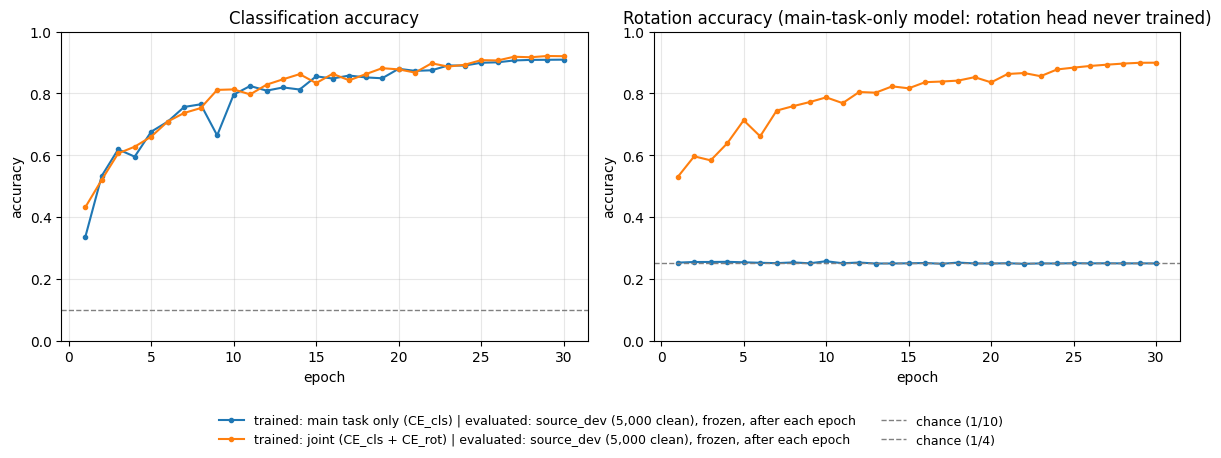

saved /kaggle/working/ttt_runs/results/figures/fig1_source_training.png


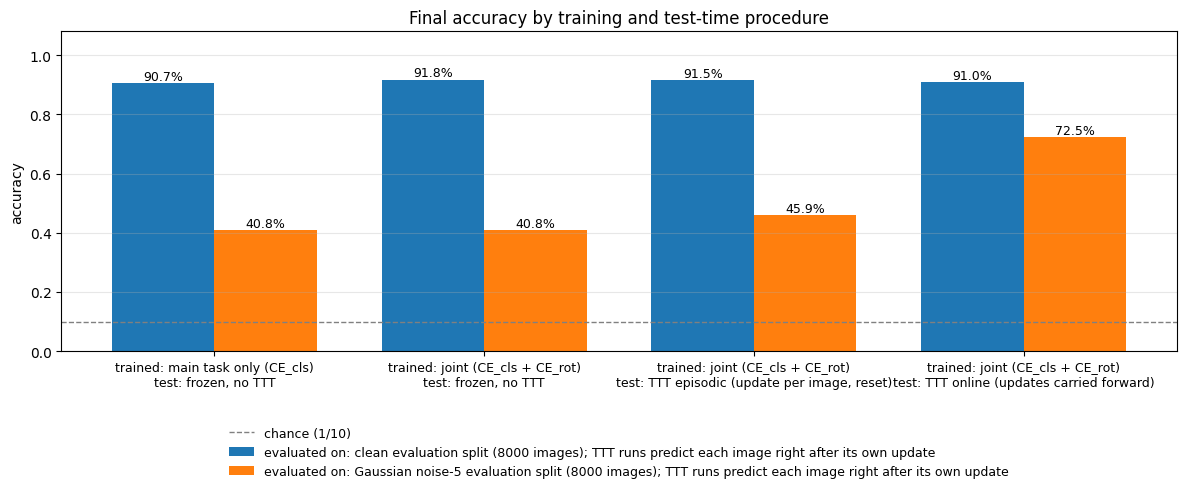

saved /kaggle/working/ttt_runs/results/figures/fig2_final_accuracy.png


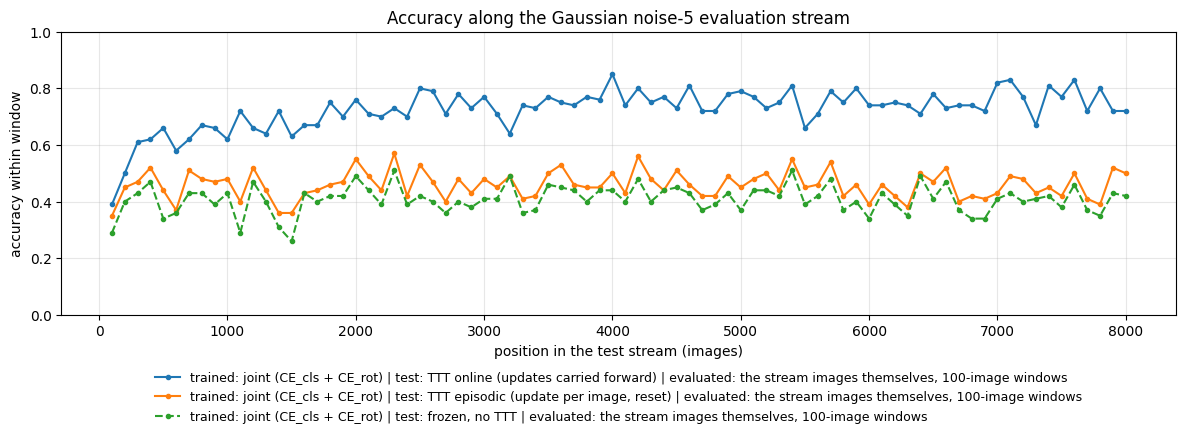

saved /kaggle/working/ttt_runs/results/figures/fig3_stream_accuracy.png


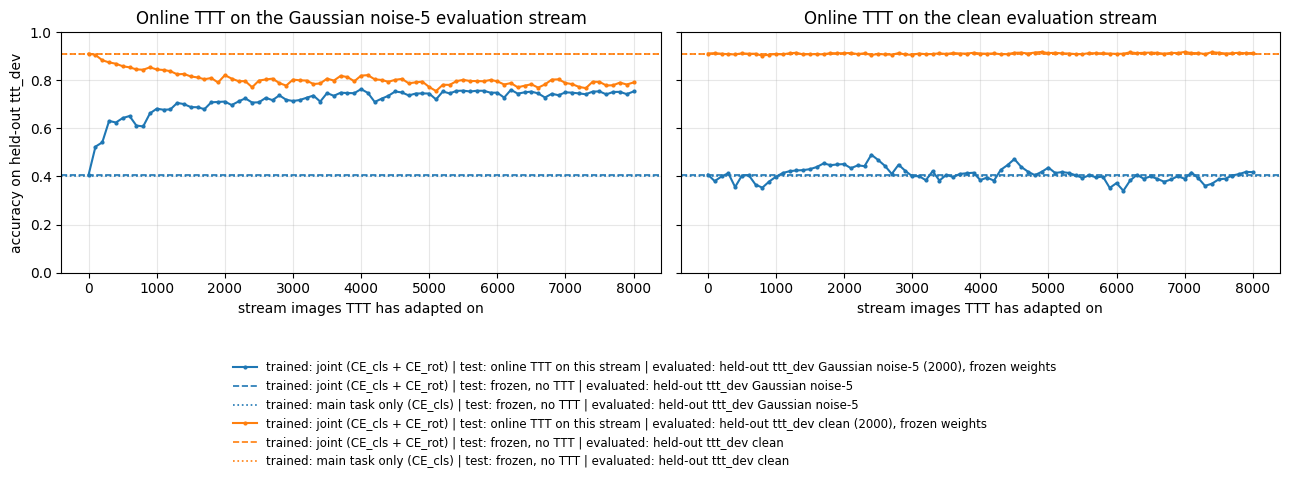

saved /kaggle/working/ttt_runs/results/figures/fig4_heldout_curve.png


In [10]:
import matplotlib.pyplot as plt
FIG_DIR = os.path.join(RES_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.3})

TRAINED = {'supervised': 'trained: main task only (CE_cls)', 'joint': 'trained: joint (CE_cls + CE_rot)'}
TESTED = {'frozen': 'test: frozen, no TTT',
          'ttt_episodic': 'test: TTT episodic (update per image, reset)',
          'ttt_online': 'test: TTT online (updates carried forward)'}
NICE = {'clean': 'clean', CORR_KEY: CORR_KEY.replace('gaussian_noise', 'Gaussian noise')}

def savefig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()
    print('saved', path)

# ---- Figure 1: source training curves ----
if sup_hist is not None and joint_hist is not None:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    for hist, kind in ((sup_hist, 'supervised'), (joint_hist, 'joint')):
        lab = TRAINED[kind] + ' | evaluated: source_dev (5,000 clean), frozen, after each epoch'
        ax[0].plot(hist['epoch'], hist['source_dev_acc'], marker='.', label=lab)
        ax[1].plot(hist['epoch'], hist['source_dev_rot_acc'], marker='.', label=lab)
    ax[0].axhline(0.1, ls='--', c='gray', lw=1, label='chance (1/10)')
    ax[1].axhline(0.25, ls='--', c='gray', lw=1, label='chance (1/4)')
    ax[0].set(title='Classification accuracy', xlabel='epoch', ylabel='accuracy', ylim=(0, 1))
    ax[1].set(title='Rotation accuracy (main-task-only model: rotation head never trained)', xlabel='epoch', ylabel='accuracy', ylim=(0, 1))
    h, l = ax[1].get_legend_handles_labels()
    h0, l0 = ax[0].get_legend_handles_labels()
    fig.legend(h[:2] + [h0[2], h[2]], l[:2] + [l0[2], l[2]], loc='lower center', ncol=2, frameon=False, fontsize=9)
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    savefig(fig, 'fig1_source_training.png')
else:
    print('Training histories not available (checkpoints reused without logs); skipping figure 1.')

# ---- Figure 2: final accuracy, every bar = (training, test-time procedure) ----
runs = [('supervised', 'frozen'), ('joint', 'frozen'), ('joint', 'ttt_episodic'), ('joint', 'ttt_online')]
x = np.arange(len(runs)); w = 0.38
fig, ax = plt.subplots(figsize=(12, 5.2))
for j, key in enumerate(EVAL):
    vals = [get(key, m + '_' + t)['accuracy'] for m, t in runs]
    bars = ax.bar(x + (j - 0.5) * w, vals, w,
                  label='evaluated on: %s evaluation split (%d images); TTT runs predict each image right after its own update' % (NICE[key], len(eval_idx)))
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, '%.1f%%' % (100 * b.get_height()), ha='center', fontsize=9)
ax.axhline(0.1, ls='--', c='gray', lw=1, label='chance (1/10)')
ax.set_xticks(x)
ax.set_xticklabels([TRAINED[m] + NL + TESTED[t] for m, t in runs], fontsize=9)
ax.set(ylabel='accuracy', ylim=(0, 1.08), title='Final accuracy by training and test-time procedure')
ax.grid(axis='x', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=1, frameon=False, fontsize=9)
fig.tight_layout()
savefig(fig, 'fig2_final_accuracy.png')

# ---- Figure 3: accuracy along the noisy stream (each image scored right after its own update) ----
win = CFG['monitor_every']
y_s, order_s = PRED[CORR_KEY + '/labels'], PRED[CORR_KEY + '/online_order']
n_w = len(y_s) // win
fig, ax = plt.subplots(figsize=(12, 4.6))
for run, style in (('joint_ttt_online', '-'), ('joint_ttt_episodic', '-'), ('joint_frozen', '--')):
    t = run.replace('joint_', '')
    ok = (PRED[CORR_KEY + '/' + run] == y_s)[order_s][:n_w * win]
    ax.plot((np.arange(n_w) + 1) * win, ok.reshape(n_w, win).mean(1), ls=style, marker='.',
            label='%s | %s | evaluated: the stream images themselves, %d-image windows' % (TRAINED['joint'], TESTED[t], win))
ax.set(title='Accuracy along the %s evaluation stream' % NICE[CORR_KEY], xlabel='position in the test stream (images)',
       ylabel='accuracy within window', ylim=(0, 1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.16), frameon=False, fontsize=9)
fig.tight_layout()
savefig(fig, 'fig3_stream_accuracy.png')

# ---- Figure 4: held-out ttt_dev accuracy vs number of stream images adapted on ----
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
colors = {CORR_KEY: 'C0', 'clean': 'C1'}
for a, stream in zip(ax, (CORR_KEY, 'clean')):
    for held in (CORR_KEY, 'clean'):
        s = hc[(hc['stream'] == stream) & (hc['heldout_set'] == held)].sort_values('images_adapted')
        a.plot(s['images_adapted'], s['accuracy'], c=colors[held], marker='.', ms=4,
               label='%s | test: online TTT on this stream | evaluated: held-out ttt_dev %s (%d), frozen weights' % (
                   TRAINED['joint'], NICE[held], len(ttt_dev_idx)))
        for model, ls in (('joint', '--'), ('supervised', ':')):
            r = HELDOUT_REF[(HELDOUT_REF['model'] == model) & (HELDOUT_REF['heldout_set'] == held)]['accuracy'].iloc[0]
            a.axhline(r, c=colors[held], ls=ls, lw=1.2,
                      label='%s | %s | evaluated: held-out ttt_dev %s' % (TRAINED[model], TESTED['frozen'], NICE[held]))
    a.set(title='Online TTT on the %s evaluation stream' % NICE[stream], xlabel='stream images TTT has adapted on',
          ylim=(0, 1))
ax[0].set_ylabel('accuracy on held-out ttt_dev')
h, l = ax[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=1, frameon=False, fontsize=8.5)
fig.tight_layout(rect=(0, 0.3, 1, 1))
savefig(fig, 'fig4_heldout_curve.png')

## 11. Optional expansion (only after the small run above works)
Uncomment the first line to evaluate more corruptions at the same severity. This step streams the Zenodo tar once more. It reuses the checkpoints and the same TTT settings. Online TTT always runs. Episodic TTT runs only if `CFG['expand_episodic'] = True` (about 15-20 min per corruption on a T4, rough estimate).

In [11]:
# CFG['expand_corruptions'] = ALL_CORRUPTIONS      # uncomment after checking the small run

if CFG['expand_corruptions']:
    names = [c for c in CFG['expand_corruptions'] if c in ALL_CORRUPTIONS]
    fetch_cifar10c(names, C10C_DIR)
    exp_rows, exp_path = [], os.path.join(RES_DIR, 'results_expanded.csv')
    for name in names:
        xcn, ycn = load_c10c(name, CFG['severity'], C10C_DIR)
        assert np.array_equal(ycn, yte)
        X, y = to_u8(xcn[eval_idx]).to(DEV), yte[eval_idx]
        del xcn
        common = {'dataset': '%s-%d' % (name, CFG['severity']), 'corruption': name, 'severity': CFG['severity']}
        print('==', common['dataset'], '==')
        p_joint = predict(joint_model, X)
        exp_rows.append(result_row('supervised', 'frozen', 'none', predict(sup_model, X), y, p_joint, common, {}))
        exp_rows.append(result_row('joint', 'frozen', 'none', p_joint, y, p_joint, common,
                                   {'rot_acc_frozen': rotation_accuracy(joint_model, X)}))
        order = np.random.RandomState(SEEDS['online_stream_order']).permutation(len(X))
        p, info = run_ttt(joint_model, X, 'online', CFG['online_lr'], CFG['online_steps'], order=order, tag=name,
                          update_images=CFG['online_update_images'])
        exp_rows.append(result_row('joint', 'ttt_online', UPD_ONL, p, y, p_joint, common,
                                   {'ttt_lr': CFG['online_lr'], 'ttt_steps': CFG['online_steps'], 'seconds': info['seconds']}))
        if CFG['expand_episodic']:
            p, info = run_ttt(joint_model, X, 'episodic', CFG['episodic_lr'], CFG['episodic_steps'], tag=name)
            exp_rows.append(result_row('joint', 'ttt_episodic', UPD_EPI, p, y, p_joint, common,
                                       {'ttt_lr': CFG['episodic_lr'], 'ttt_steps': CFG['episodic_steps'], 'seconds': info['seconds']}))
        del X
        pd.DataFrame(exp_rows).to_csv(exp_path, index=False)   # saved after every corruption
    exp_df = pd.DataFrame(exp_rows)
    display(exp_df.pivot_table(index='dataset', columns='run', values='accuracy'))
else:
    print('Expansion skipped. Check the summary above first, then uncomment the first line of this cell and re-run it.')

Expansion skipped. Check the summary above first, then uncomment the first line of this cell and re-run it.


## 12. Failures and setup limits → notes.md

In [12]:
LIMITS = [
    'One training seed per model. McNemar p-values cover test-image sampling only, not training-seed variance. Re-run with other seeds before drawing strong conclusions.',
    'TTT settings are the paper defaults (lr 1e-3; 10 steps episodic, 1 step online).',
    'ttt_dev is never adapted on. Its pictures are disjoint from the stream, but they come from the same corruption, so the held-out curve measures generalisation within this shift, not to new shifts.',
    'The held-out curve is scored with the weights at that point in the stream, with no TTT on the held-out images themselves.',
    'Clean and corrupted evaluation use the same underlying test images, so the comparisons are paired.',
    'The backbone is a small 3-stage residual net, not the ResNet-26 used by Sun et al. (2020), so absolute numbers will differ from the paper.',
    'The main-task-only model (supervised in code) has an untrained rotation branch, so TTT is only run on the joint model.',
    'Online TTT results depend on stream order. One fixed seeded order was used.',
    'AMP and cudnn.benchmark are on during training, so re-runs are close but not bit-identical.',
    'Only stages 1-2 (shared extractor) are updated at test time. Both stage-3 copies and both heads are frozen, and this is checked after every TTT run.',
]
auto = list(NOTES)
try:
    rc = get(CORR_KEY, 'joint_frozen')['rot_acc_frozen']
    if rc < 0.5:
        auto.append('Joint model rotation accuracy on %s is only %.3f, so the self-supervised signal is weak on this shift.' % (CORR_KEY, rc))
    if not df['heads_frozen_ok'].dropna().astype(bool).all():
        auto.append('Frozen-parameter check FAILED for at least one TTT run.')
    for run in ('joint_ttt_episodic', 'joint_ttt_online'):
        r = get('clean', run)
        if r['delta_vs_joint_frozen'] < 0 and r['mcnemar_p_vs_joint_frozen'] < 0.05:
            auto.append('%s significantly lowers clean accuracy (%+.2f pts).' % (run, 100 * r['delta_vs_joint_frozen']))
except NameError as e:
    auto.append('Results were not produced (pipeline stopped early): %s' % e)

NOTES_MD = NL.join(['# Notes: failures and setup limits', '', '## Detected during this run'] +
                   (['- ' + a for a in auto] if auto else ['- none']) +
                   ['', '## Setup limits'] + ['- ' + s for s in LIMITS])
with open(os.path.join(RES_DIR, 'notes.md'), 'w') as f:
    f.write(NOTES_MD + NL)
display(Markdown(NOTES_MD))
save_config({'notes': auto})
print('All outputs are in', CFG['out_dir'])
for root, _, files in os.walk(CFG['out_dir']):
    for fn in sorted(files):
        print('  ', os.path.join(root, fn))

# Notes: failures and setup limits

## Detected during this run
- joint_ttt_online significantly lowers clean accuracy (-0.72 pts).

## Setup limits
- One training seed per model. McNemar p-values cover test-image sampling only, not training-seed variance. Re-run with other seeds before drawing strong conclusions.
- TTT settings are the paper defaults (lr 1e-3; 10 steps episodic, 1 step online).
- ttt_dev is never adapted on. Its pictures are disjoint from the stream, but they come from the same corruption, so the held-out curve measures generalisation within this shift, not to new shifts.
- The held-out curve is scored with the weights at that point in the stream, with no TTT on the held-out images themselves.
- Clean and corrupted evaluation use the same underlying test images, so the comparisons are paired.
- The backbone is a small 3-stage residual net, not the ResNet-26 used by Sun et al. (2020), so absolute numbers will differ from the paper.
- The main-task-only model (supervised in code) has an untrained rotation branch, so TTT is only run on the joint model.
- Online TTT results depend on stream order. One fixed seeded order was used.
- AMP and cudnn.benchmark are on during training, so re-runs are close but not bit-identical.
- Only stages 1-2 (shared extractor) are updated at test time. Both stage-3 copies and both heads are frozen, and this is checked after every TTT run.

All outputs are in /kaggle/working/ttt_runs
   /kaggle/working/ttt_runs/config.json
   /kaggle/working/ttt_runs/splits.npz
   /kaggle/working/ttt_runs/checkpoints/joint_best.pt
   /kaggle/working/ttt_runs/checkpoints/joint_last.pt
   /kaggle/working/ttt_runs/checkpoints/supervised_best.pt
   /kaggle/working/ttt_runs/checkpoints/supervised_last.pt
   /kaggle/working/ttt_runs/logs/joint_history.csv
   /kaggle/working/ttt_runs/logs/supervised_history.csv
   /kaggle/working/ttt_runs/results/heldout_curve.csv
   /kaggle/working/ttt_runs/results/notes.md
   /kaggle/working/ttt_runs/results/predictions.npz
   /kaggle/working/ttt_runs/results/results.csv
   /kaggle/working/ttt_runs/results/source_results.csv
   /kaggle/working/ttt_runs/results/split.csv
   /kaggle/working/ttt_runs/results/summary.md
   /kaggle/working/ttt_runs/results/figures/fig1_source_training.png
   /kaggle/working/ttt_runs/results/figures/fig2_final_accuracy.png
   /kaggle/working/ttt_runs/results/figures/fig3_stream_accu